# 1 — Skeleton e coeficientes da forma polinomial ordenada

**Pergunta:** quando expandimos uma AST de somas e produtos, obtemos uma lista esparsa e ordenada dos termos que preserva a função original? Cada linha abaixo traz a motivação do exemplo, a fórmula sorteada/construída, o skeleton realizado e seus coeficientes. Os gráficos confrontam a AST original com a forma expandida no mesmo histórico.



**Resumo científico:** os 16 exemplos construídos e as 20 árvores iniciais passaram em 31 históricos cada (rtol=atol=1e-12). A revisão exata encontrou zero discordâncias com SymPy nas 548 árvores pequenas (93 funções distintas) e nas 247 árvores aleatórias aceitas; 3 foram rejeitadas por grau. Nas 15.808 avaliações independentes, o maior erro absoluto foi 1.332268e-15. Os casos de borda e as rejeições passaram. O exemplo de cancelamento catastrófico demonstra que a equivalência algébrica exata não implica igualdade bit a bit da execução em float. A referência numérica é canonical_key, preservando a proveniência separadamente. O mesmo comando de reprodução executa toda a revisão e os onze casos grandes.

**Convenção:** `s_j[t-k]` é o valor da série `j` em `t-k`. Uma chave vazia `()` é a constante; `((0,1),(2,2))` é a interação `s_0[t-1] s_2[t-2]`. O skeleton reporta somente coeficientes realizados não nulos. A inovação aleatória da trajetória não faz parte da função determinística aqui expandida.

**Protocolo de tempo por linha:** 50 execuções de aquecimento, seguidas por exatamente 5.000 chamadas completas a `canonicalize_polynomial`, divididas em 10 blocos de 500. A coluna de tempo é a soma dos tempos dos blocos dividida por 5.000, em µs por transformação. Inclui validação dos bindings, expansão, cálculo exato de coeficientes e montagem da saída, com overhead de chamada e laço. Sorteio das árvores, geração/avaliação das séries, SymPy, formatação e gráficos ficam fora da medição. As mesmas entradas são reutilizadas sem cache de resultados. O garbage collector permanece na configuração normal do kernel. O desvio entre médias dos blocos é mostrado ao final como variabilidade da medição; não é o desvio de 5.000 tempos individuais. Os tempos dependem do hardware e da carga da máquina e são recalculados ao executar o notebook.

**Caso extremo adicional (2026-10-28):** `(1 + soma de s_j[t-lag], j=0..2, lag=1..6)^4`, implementado como produto binário balanceado de quatro somas idênticas. Configuração determinística: 18 átomos de lag, constante 1, grau máximo 4, 75 operadores (151 nós), 7.315 monômios de saída. O suporte completo e todos os coeficientes são verificados pela fórmula multinomial antes da cronometragem. O mesmo protocolo de 50 aquecimentos e 5.000 transformações é aplicado. Esse é o suporte máximo para 18 variáveis formais e grau até quatro; o comprimento da AST em geral pode crescer arbitrariamente por repetição de termos. O teste ultrapassa propositalmente o limite de operadores do sorteador das tabelas anteriores. Para reproduzir todo o notebook com esse caso pesado, use `timeout=1800` no comando acima.

**Resultados desta execução:** os dez intermediários, com 15 a 3.876 termos, passaram na verificação multinomial exata e tiveram médias de 0,373 a 77,621 ms por transformação. O caso extremo passou na mesma verificação para 7.315 termos: média de 161,711 ms em 5.000 transformações. A tabela consolidada tem 72 linhas e 360.000 transformações cronometradas. Os gráficos relacionam número de lags, termos expandidos e tempo.

**Série intermediária adicionada:** dez expressões da família `A_m^4`, onde `A_m=1+∑_{i=1}^m z_i` e os `z_i` percorrem, em ordem, os 18 lags de três séries e seis atrasos. Os valores de `m` são 2, 3, 4, 5, 6, 8, 9, 10, 12 e 15. Cada caso usa 50 aquecimentos e 5.000 medições; os monômios e coeficientes são confrontados exatamente com a fórmula multinomial. A escolha cobre saídas de 15 a 3.876 termos antes do caso de 7.315. Todos os casos usam constante 1. A nova tabela e os gráficos foram adicionados entre os casos anteriores e o extremo.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(root / 'src'))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tsfmxai.representations import Add, Multiply, Lag, Parameter, Tanh, MechanismBinding, canonicalize_polynomial, format_canonical_polynomial, to_bound_formula
from tsfmxai.generators.random_expression import RandomTreeConfig, sample_random_mechanism
from tsfmxai.generators.trajectory import evaluate_bound_expression
def add(*parts):
    result = parts[0]
    for part in parts[1:]: result = Add(result, part)
    return result
def mul(*parts):
    result = parts[0]
    for part in parts[1:]: result = Multiply(result, part)
    return result
def case(name, expression, parameters, lags, motivation):
    return dict(name=name, expression=expression, binding=MechanismBinding(parameters, lags), motivation=motivation)
u, v, w, z = Lag(0,'U'), Lag(1,'V'), Lag(2,'W'), Lag(0,'Z')
print('Raiz:', root, '| Python:', sys.version.split()[0])
from time import perf_counter_ns
import platform
from tsfmxai.representations import operator_count
TIMING_REPETITIONS, TIMING_BLOCKS, TIMING_WARMUP = 5000, 10, 50
timing_records = []

def benchmark_transform(expression, binding, label, *, progress=False):
    normal = canonicalize_polynomial(expression, binding)
    for _ in range(TIMING_WARMUP):
        canonicalize_polynomial(expression, binding)
    per_block = TIMING_REPETITIONS // TIMING_BLOCKS
    block_means_us = []
    for block_index in range(TIMING_BLOCKS):
        start = perf_counter_ns()
        for _ in range(per_block):
            canonicalize_polynomial(expression, binding)
        block_means_us.append((perf_counter_ns() - start) / per_block / 1000)
        if progress:
            print(f'{label}: {(block_index+1)*per_block}/{TIMING_REPETITIONS} transformações; média do bloco {block_means_us[-1]/1000:.3f} ms', flush=True)
    mean_us = float(np.mean(block_means_us))
    timing_records.append({
        'Caso': label, 'Transformações': TIMING_REPETITIONS,
        'Operadores AST': operator_count(expression), 'Termos de saída': len(normal.terms),
        'Média (µs/transformação)': mean_us,
        'DP das médias dos 10 blocos (µs)': float(np.std(block_means_us, ddof=1)),
        'Tempo total das 5.000 (s)': mean_us * TIMING_REPETITIONS / 1e6,
    })
    return {'Operadores AST': operator_count(expression),
            'Termos de saída': len(normal.terms),
            'Tempo médio em 5.000 (µs/transformação)': mean_us}

print('Ambiente dos tempos:', platform.platform(), '| CPU:', platform.processor(),
      '| NumPy:', np.__version__)


Raiz: C:\Users\mateu\repos\tsfmxai | Python: 3.11.9
Ambiente dos tempos: Windows-10-10.0.19045-SP0 | CPU: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel | NumPy: 1.26.4


O código acima importa a biblioteca reutilizável e define apenas atalhos para construir os casos de demonstração; o algoritmo de canonização não está duplicado no notebook.

In [2]:
cases = [
 case('01 Constante', Parameter('a'), {'a':2.0}, {}, 'Mostra o termo independente, de grau zero.'),
 case('02 Um lag', u, {}, {'U':1}, 'Mostra um monômio sem coeficiente explícito: vale 1.'),
 case('03 Offset + lag', add(Parameter('a'), u), {'a':-1.5}, {'U':1}, 'Confere que a constante aparece antes do lag.'),
 case('04 Lags fora de ordem', add(v,u), {}, {'U':2,'V':1}, 'A ordem depende de série e lag, não da ordem da AST.'),
 case('05 Alias de lag', add(u,z), {}, {'U':1,'Z':1}, 'Slots diferentes com mesmo lag resolvido somam coeficientes.'),
 case('06 Mesmo lag ao quadrado', mul(u,z), {}, {'U':1,'Z':1}, 'Fatores repetidos são mantidos como multiplicidade.'),
 case('07 Interação multivariada', mul(v,u), {}, {'U':1,'V':2}, 'A interação preserva ambas as séries, ordenadas globalmente.'),
 case('08 Distribuição simples', mul(add(u,Parameter('a')),v), {'a':2.0}, {'U':1,'V':1}, 'Produto de soma gera termo simples e interação.'),
 case('09 Duas somas', mul(add(u,Parameter('a')),add(v,Parameter('b'))), {'a':2.0,'b':3.0}, {'U':1,'V':2}, 'Expansão completa produz constante, dois lags e interação.'),
 case('10 Termos iguais após expansão', mul(add(u,v),add(u,v)), {}, {'U':1,'V':2}, 'Os dois produtos cruzados devem formar coeficiente 2.'),
 case('11 Coeficiente zero', add(mul(Parameter('a'),u),Parameter('b')), {'a':0.0,'b':2.0}, {'U':1}, 'Skeleton potencial inclui lag; o realizado não inclui.'),
 case('12 Cancelamento numérico', add(mul(Parameter('a'),u),mul(Parameter('b'),z)), {'a':0.125,'b':-0.125}, {'U':1,'Z':1}, 'Termos com mesma chave se cancelam exatamente.'),
 case('13 Dependências negativas', add(mul(Parameter('a'),u),mul(Parameter('b'),v)), {'a':-0.5,'b':1.25}, {'U':1,'V':2}, 'Os sinais permanecem nos coeficientes.'),
 case('14 Grau três', mul(u,v,w), {}, {'U':1,'V':2,'W':3}, 'Três séries e três atrasos em uma interação.'),
 case('15 Grau quatro', mul(u,v,w,z), {}, {'U':1,'V':2,'W':3,'Z':2}, 'A fronteira admitida: quatro fatores de lag.'),
 case('16 Distribuição cúbica', mul(add(u,Parameter('a')),add(v,Parameter('b')),add(w,Parameter('c'))), {'a':1.0,'b':-0.5,'c':2.0}, {'U':1,'V':2,'W':3}, 'Três somas originam oito termos em vários graus.'),
]
assert len(cases) == 16
print('Casos planejados:', len(cases))

Casos planejados: 16


Os 16 casos acima foram escolhidos para isolar constante, ordenação, aliases, multiplicidade, interações, distributividade, zeros, sinais e o limite de quatro fatores. A motivação específica acompanha cada linha da tabela seguinte.

In [3]:
def evaluate_case(item, grid):
    normal = canonicalize_polynomial(item['expression'], item['binding'])
    sources = {atom[0] for key in normal.potential_skeleton for atom in key}
    sources.update(node.variable for node in _lags(item['expression']))
    original, canonical = [], []
    for q in grid:
        histories = {j:[0.5*q + 0.1*j, -0.75*q + 0.2*j, q*(1+0.2*j)] for j in sources}
        original.append(evaluate_bound_expression(item['expression'],item['binding'],time=3,histories=histories))
        canonical.append(normal.evaluate(histories))
    return normal, np.asarray(original), np.asarray(canonical)
def _lags(node):
    if isinstance(node,Lag): return [node]
    if isinstance(node,Parameter): return []
    if isinstance(node,Tanh): return _lags(node.operand)
    return _lags(node.left)+_lags(node.right)
grid=np.linspace(-1.2,1.2,31)
results=[]
for item in cases:
    normal, original, canonical = evaluate_case(item,grid)
    error=float(np.max(np.abs(original-canonical)))
    assert np.allclose(original,canonical,rtol=1e-12,atol=1e-12), item['name']
    results.append(dict(Caso=item['name'], Motivação=item['motivation'], **{'AST de entrada':to_bound_formula(item['expression'],item['binding']), 'Forma padronizada':format_canonical_polynomial(normal), 'Skeleton realizado':str(normal.skeleton), 'Coeficientes':str(tuple(round(x,6) for x in normal.coefficients)), 'Erro máximo':error}, **benchmark_transform(item['expression'], item['binding'], item['name'])))
pd.set_option('display.max_colwidth',None)
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)
display(pd.DataFrame(results))

,Caso,Motivação,AST de entrada,Forma padronizada,Skeleton realizado,Coeficientes,Erro máximo,Operadores AST,Termos de saída,Tempo médio em 5.000 (µs/transformação)
0,01 Constante,"Mostra o termo independente, de grau zero.",2,2,"((),)","(2.0,)",0.000000e+00,0,1,18.37496
1,02 Um lag,Mostra um monômio sem coeficiente explícito: vale 1.,x_0(t-1),(1)*s_0[t-1],"(((0, 1),),)","(1.0,)",0.000000e+00,0,1,12.23560
2,03 Offset + lag,Confere que a constante aparece antes do lag.,(-1.5 + x_0(t-1)),-1.5 + (1)*s_0[t-1],"((), ((0, 1),))","(-1.5, 1.0)",0.000000e+00,1,2,29.09664
3,04 Lags fora de ordem,"A ordem depende de série e lag, não da ordem da AST.",(x_1(t-1) + x_0(t-2)),(1)*s_0[t-2] + (1)*s_1[t-1],"(((0, 2),), ((1, 1),))","(1.0, 1.0)",0.000000e+00,1,2,28.50562
4,05 Alias de lag,Slots diferentes com mesmo lag resolvido somam coeficientes.,(x_0(t-1) + x_0(t-1)),(2)*s_0[t-1],"(((0, 1),),)","(2.0,)",0.000000e+00,1,1,18.46626
5,06 Mesmo lag ao quadrado,Fatores repetidos são mantidos como multiplicidade.,(x_0(t-1) * x_0(t-1)),(1)*s_0[t-1] * s_0[t-1],"(((0, 1), (0, 1)),)","(1.0,)",0.000000e+00,1,1,20.57656
6,07 Interação multivariada,"A interação preserva ambas as séries, ordenadas globalmente.",(x_1(t-2) * x_0(t-1)),(1)*s_0[t-1] * s_1[t-2],"(((0, 1), (1, 2)),)","(1.0,)",0.000000e+00,1,1,20.92662
7,08 Distribuição simples,Produto de soma gera termo simples e interação.,((x_0(t-1) + 2) * x_1(t-1)),(2)*s_1[t-1] + (1)*s_0[t-1] * s_1[t-1],"(((1, 1),), ((0, 1), (1, 1)))","(2.0, 1.0)",4.440892e-16,2,2,41.99138
8,09 Duas somas,"Expansão completa produz constante, dois lags e interação.",((x_0(t-1) + 2) * (x_1(t-2) + 3)),6 + (3)*s_0[t-1] + (2)*s_1[t-2] + (1)*s_0[t-1] * s_1[t-2],"((), ((0, 1),), ((1, 2),), ((0, 1), (1, 2)))","(6.0, 3.0, 2.0, 1.0)",8.881784e-16,3,4,69.63366
9,10 Termos iguais após expansão,Os dois produtos cruzados devem formar coeficiente 2.,((x_0(t-1) + x_1(t-2)) * (x_0(t-1) + x_1(t-2))),(1)*s_0[t-1] * s_0[t-1] + (2)*s_0[t-1] * s_1[t-2] + (1)*s_1[t-2] * s_1[t-2],"(((0, 1), (0, 1)), ((0, 1), (1, 2)), ((1, 2), (1, 2)))","(1.0, 2.0, 1.0)",1.808449e-16,3,3,53.65718


A tabela registra o resultado final de cada fórmula e compara as duas avaliações em 31 históricos. O erro máximo é diagnóstico numérico de equivalência; os coeficientes exatos são armazenados como `Fraction` pela biblioteca antes da apresentação decimal.

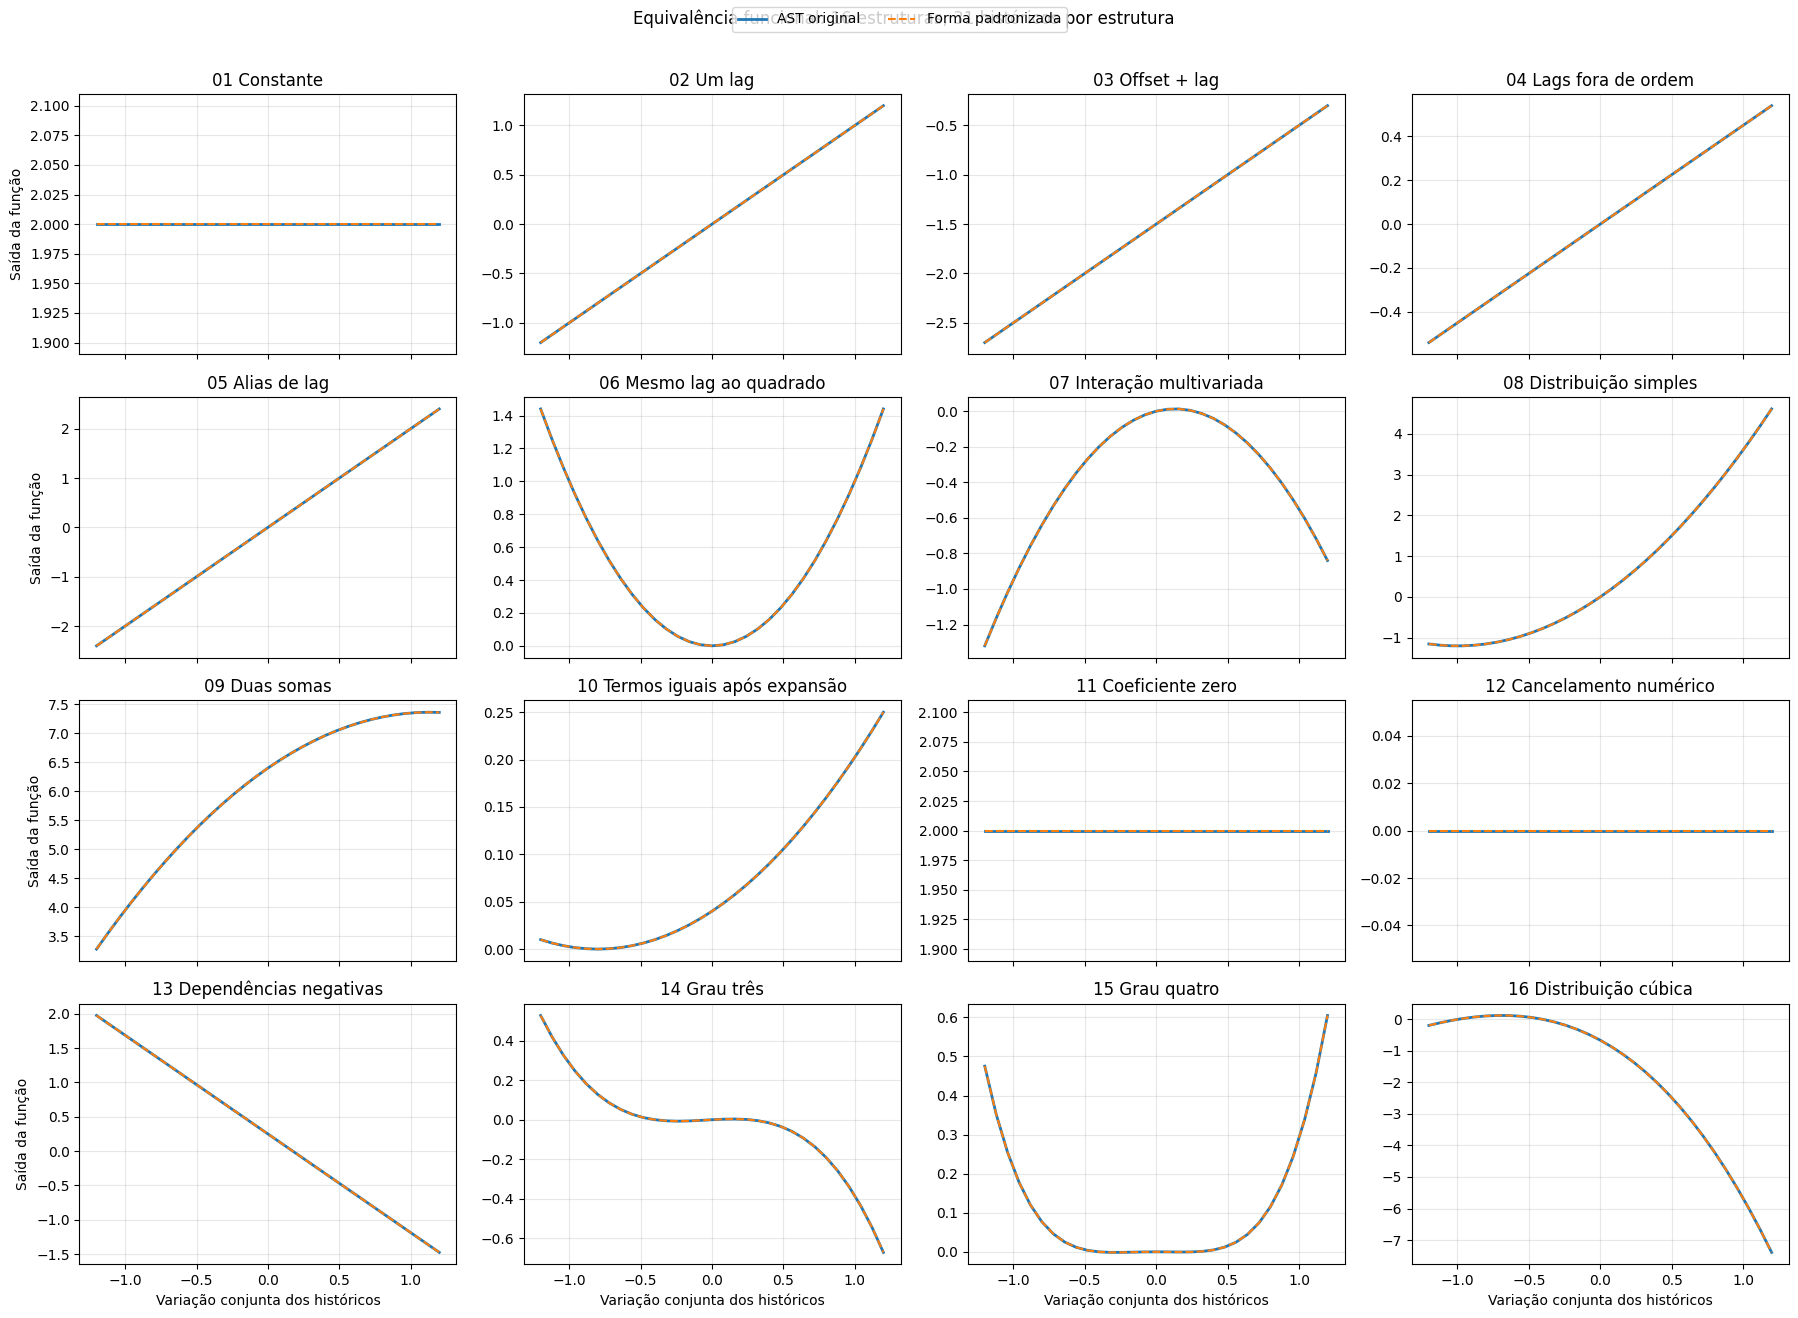

In [4]:
fig, axes = plt.subplots(4,4,figsize=(18,13),sharex=True)
for ax,item in zip(axes.flat,cases):
    _,original,canonical=evaluate_case(item,grid)
    ax.plot(grid,original,lw=2,label='AST original')
    ax.plot(grid,canonical,'--',lw=1.5,label='Forma padronizada')
    ax.set_title(item['name']); ax.grid(alpha=.3)
for ax in axes[-1]: ax.set_xlabel('Variação conjunta dos históricos')
for ax in axes[:,0]: ax.set_ylabel('Saída da função')
fig.legend(*axes.flat[0].get_legend_handles_labels(),loc='upper center',ncol=2)
fig.suptitle('Equivalência funcional: 16 estruturas, 31 históricos por estrutura',y=1.01)
fig.tight_layout(); plt.show()

Cada painel corresponde à linha de mesmo número da tabela. As curvas coincidentes indicam que a avaliação da forma expandida preservou a função nos históricos testados; isso complementa, mas não substitui, os testes algébricos unitários.

In [5]:
config=RandomTreeConfig(minimum_operators=2,maximum_operators=5,num_series=3,minimum_lag=1,maximum_lag=3,parameter_probability=.4,lag_probability=.6,require_lag=True)
random_rows=[]; rejected=[]
for seed in range(173,193):
    sampled=sample_random_mechanism(config,seed=seed)
    try: normal=canonicalize_polynomial(sampled.expression,sampled.binding)
    except ValueError as exc:
        rejected.append((seed,str(exc))); continue
    item=dict(expression=sampled.expression,binding=sampled.binding)
    _,original,canonical=evaluate_case(item,grid)
    error=float(np.max(np.abs(original-canonical)))
    assert np.allclose(original,canonical,rtol=1e-12,atol=1e-12),seed
    random_rows.append({'Seed':seed,'Motivação':'AST realmente sorteada; verifica generalização fora dos casos manuais.', 'AST de entrada':sampled.formula,'Forma padronizada':format_canonical_polynomial(normal),'Skeleton realizado':str(normal.skeleton),'Coeficientes':str(tuple(round(x,5) for x in normal.coefficients)),'Erro máximo':error, **benchmark_transform(sampled.expression, sampled.binding, f'Seed {seed}')})
display(pd.DataFrame(random_rows)); print('Aceitas:',len(random_rows),'| Rejeitadas por grau:',rejected)

,Seed,Motivação,AST de entrada,Forma padronizada,Skeleton realizado,Coeficientes,Erro máximo,Operadores AST,Termos de saída,Tempo médio em 5.000 (µs/transformação)
0,173,AST realmente sorteada; verifica generalização fora dos casos manuais.,(((((x_0(t-3) + -0.65358) * x_0(t-3)) + -0.615051) + x_0(t-1)) + x_1(t-2)),-0.615051 + (1)*s_0[t-1] + (-0.65358)*s_0[t-3] + (1)*s_1[t-2] + (1)*s_0[t-3] * s_0[t-3],"((), ((0, 1),), ((0, 3),), ((1, 2),), ((0, 3), (0, 3)))","(-0.61505, 1.0, -0.65358, 1.0, 1.0)",2.775558e-16,5,5,93.03886
1,174,AST realmente sorteada; verifica generalização fora dos casos manuais.,(((x_2(t-2) * x_2(t-2)) + x_1(t-3)) * 0.0997927),(0.0997927)*s_1[t-3] + (0.0997927)*s_2[t-2] * s_2[t-2],"(((1, 3),), ((2, 2), (2, 2)))","(0.09979, 0.09979)",1.387779e-17,3,2,57.09524
2,175,AST realmente sorteada; verifica generalização fora dos casos manuais.,((x_1(t-1) * (0.847324 * (0.255622 * 0.203405))) * -0.335899),(-0.0147985)*s_1[t-1],"(((1, 1),),)","(-0.0148,)",1.734723e-18,4,1,68.51638
3,176,AST realmente sorteada; verifica generalização fora dos casos manuais.,(-0.641599 + (x_2(t-3) + x_0(t-1))),-0.641599 + (1)*s_0[t-1] + (1)*s_2[t-3],"((), ((0, 1),), ((2, 3),))","(-0.6416, 1.0, 1.0)",2.220446e-16,2,3,49.83162
4,177,AST realmente sorteada; verifica generalização fora dos casos manuais.,((-0.441511 + ((x_1(t-1) + x_2(t-1)) + x_2(t-1))) * 0.501501),-0.221418 + (0.501501)*s_1[t-1] + (1.003)*s_2[t-1],"((), ((1, 1),), ((2, 1),))","(-0.22142, 0.5015, 1.003)",4.440892e-16,4,3,88.09998
5,178,AST realmente sorteada; verifica generalização fora dos casos manuais.,((0.442765 * (-0.541247 + (x_2(t-3) * -0.835406))) + x_2(t-3)),-0.239645 + (0.630112)*s_2[t-3],"((), ((2, 3),))","(-0.23964, 0.63011)",5.551115e-17,4,2,84.77330
6,179,AST realmente sorteada; verifica generalização fora dos casos manuais.,((x_2(t-3) + x_0(t-3)) * (-0.774008 + ((x_2(t-1) * -0.671365) + 0.118919))),(-0.65509)*s_0[t-3] + (-0.65509)*s_2[t-3] + (-0.671365)*s_0[t-3] * s_2[t-1] + (-0.671365)*s_2[t-1] * s_2[t-3],"(((0, 3),), ((2, 3),), ((0, 3), (2, 1)), ((2, 1), (2, 3)))","(-0.65509, -0.65509, -0.67136, -0.67136)",4.440892e-16,5,4,120.74470
7,180,AST realmente sorteada; verifica generalização fora dos casos manuais.,((x_1(t-1) * x_1(t-1)) * 0.22133),(0.22133)*s_1[t-1] * s_1[t-1],"(((1, 1), (1, 1)),)","(0.22133,)",5.551115e-17,2,1,36.88868
8,181,AST realmente sorteada; verifica generalização fora dos casos manuais.,((x_2(t-3) + x_1(t-3)) * ((x_2(t-2) * x_1(t-1)) * x_1(t-1))),(1)*s_1[t-1] * s_1[t-1] * s_1[t-3] * s_2[t-2] + (1)*s_1[t-1] * s_1[t-1] * s_2[t-2] * s_2[t-3],"(((1, 1), (1, 1), (1, 3), (2, 2)), ((1, 1), (1, 1), (2, 2), (2, 3)))","(1.0, 1.0)",2.220446e-16,4,2,69.21426
9,182,AST realmente sorteada; verifica generalização fora dos casos manuais.,(((0.639302 * (x_0(t-3) * -0.427913)) * x_0(t-2)) + (0.117918 + x_0(t-1))),0.117918 + (1)*s_0[t-1] + (-0.273566)*s_0[t-2] * s_0[t-3],"((), ((0, 1),), ((0, 2), (0, 3)))","(0.11792, 1.0, -0.27357)",0.000000e+00,5,3,81.61834


Aceitas: 20 | Rejeitadas por grau: []


Esta tabela repete a análise para árvores do sorteador real. O seed é mostrado em cada linha e qualquer rejeição por grau aparece explicitamente, em vez de truncar termos da função.

In [6]:
invalid=[('Quinto fator',mul(u,u,u,u,u),MechanismBinding({}, {'U':1}),'Grau acima do contrato; não truncar.'),('Tanh de produto',Tanh(mul(u,v)),MechanismBinding({}, {'U':1,'V':2}),'Tanh não pode ser expandida como polinômio finito.') ]
rows=[]
for name,expression,binding,motivation in invalid:
    try: canonicalize_polynomial(expression,binding)
    except (ValueError,TypeError) as exc: rows.append({'Caso':name,'Motivação':motivation,'AST de entrada':to_bound_formula(expression,binding),'Resultado':type(exc).__name__+': '+str(exc)})
    else: raise AssertionError(name+' deveria ser rejeitado')
display(pd.DataFrame(rows))
print('Resumo:',len(cases),'casos manuais +',len(random_rows),'árvores sorteadas aceitas;',len(invalid),'limites de escopo verificados.')

,Caso,Motivação,AST de entrada,Resultado
0,Quinto fator,Grau acima do contrato; não truncar.,((((x_0(t-1) * x_0(t-1)) * x_0(t-1)) * x_0(t-1)) * x_0(t-1)),ValueError: Expanded monomial has degree 5; max_degree=4.
1,Tempo explícito,Time não integra a subgramática polinomial em lags.,t,TypeError: Time is outside the polynomial subgrammar.
2,Tanh de produto,Tanh não pode ser expandida como polinômio finito.,tanh((x_0(t-1) * x_1(t-2))),TypeError: Tanh is outside the polynomial subgrammar.


Resumo: 16 casos manuais + 20 árvores sorteadas aceitas; 3 limites de escopo verificados.


Os três contraexemplos encerram o estudo com as fronteiras do método: grau cinco, tempo explícito e `tanh` são rejeitados com mensagens, sem produzir um skeleton incorreto. Conclusão: a expansão esparsa reproduz as funções polinomiais testadas e fornece dois targets alinhados, mas a cobertura da AST completa depende de uma decisão futura sobre operadores não polinomiais.

## Revisão: casos de borda e validação independente

As tabelas anteriores percorrem uma linha no espaço de históricos. A revisão abaixo acrescenta históricos independentes, comparação exata com SymPy e famílias de árvores equivalentes. A identidade da **função realizada** é `canonical_key`: a lista de monômios e coeficientes racionais. A proveniência dos parâmetros e o suporte potencial continuam disponíveis e podem diferir entre árvores da mesma função.

O limite de grau vale para a expansão da entrada, antes dos cancelamentos numéricos. Assim, `0*u^5` também é rejeitado pelo contrato atual. Isto delimita as entradas aceitas; a garantia de padronização é aplicada às entradas aceitas. Coeficientes são exatos para os valores binários recebidos, enquanto a execução da AST em ponto flutuante pode sofrer arredondamento.

In [7]:
import sympy as sp
from fractions import Fraction
from tsfmxai.representations import parameter_slots, lag_slots
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

def binding_for(expression, parameters=None, lags=None):
    parameters, lags = parameters or {}, lags or {}
    return MechanismBinding(
        {slot: parameters[slot] for slot in parameter_slots(expression)},
        {slot: lags[slot] for slot in lag_slots(expression)})

def oracle_key(expression, binding):
    # Oráculo independente: SymPy recebe a AST e expande em QQ.
    atoms=sorted({(node.variable,binding.lag_values[node.slot]) for node in _lags(expression)})
    symbols={atom:sp.Symbol(f's{atom[0]}_lag{atom[1]}') for atom in atoms}
    def convert(node):
        if isinstance(node, Parameter):
            return sp.Rational(*float(binding.parameter_values[node.slot]).as_integer_ratio())
        if isinstance(node,Lag):
            return symbols[(node.variable,binding.lag_values[node.slot])]
        if isinstance(node,Add): return convert(node.left)+convert(node.right)
        if isinstance(node,Multiply): return convert(node.left)*convert(node.right)
        raise TypeError(type(node).__name__)
    expression_sp=convert(expression)
    if not atoms:
        value=sp.expand(expression_sp)
        return (((),Fraction(int(value.p),int(value.q))),) if value else ()
    poly=sp.Poly(expression_sp,*[symbols[a] for a in atoms],domain=sp.QQ)
    terms=[]
    for exponents,coefficient in poly.terms():
        if coefficient:
            key=tuple(atom for atom,power in zip(atoms,exponents) for _ in range(power))
            terms.append((key,Fraction(int(coefficient.p),int(coefficient.q))))
    return tuple(sorted(terms,key=lambda item:(len(item[0]),item[0])))

print('Oráculo independente: SymPy',sp.__version__, '| domínio racional QQ')

Oráculo independente: SymPy 1.14.0 | domínio racional QQ


O oráculo traduz a AST diretamente para SymPy e coleta seus coeficientes, sem utilizar a expansão da nossa biblioteca. Isso permite conferir a estrutura inteira, inclusive termos que uma curva de teste poderia deixar passar.

In [8]:
edge_cases=[
 case('E01 Constante zero',Parameter('a'),{'a':0.0},{},'O zero tem skeleton vazio e fórmula 0.'),
 case('E02 Zero negativo',Parameter('a'),{'a':-0.0},{},'O sinal do zero não cria um termo.'),
 case('E03 Quatro lags iguais',mul(u,u,u,u),{},{'U':1},'Preserva quatro ocorrências do mesmo lag, grau 4.'),
 case('E04 Binômio à quarta',mul(add(u,v),add(u,v),add(u,v),add(u,v)),{},{'U':1,'V':2},'16 produtos se agrupam em 5 termos; coeficientes 1,4,6,4,1.'),
 case('E05 Grau quatro com coeficiente',add(Parameter('b'),mul(Parameter('a'),u,v,w,z)),{'a':-.5,'b':2.},{'U':1,'V':2,'W':3,'Z':2},'O coeficiente e o offset não contam como fatores de lag.'),
 case('E06 Mesmo ID, atrasos distintos',add(z,u),{},{'U':2,'Z':10},'s_0[t-2] precede s_0[t-10]; ambos permanecem.'),
 case('E07 IDs 2 e 10',add(Lag(10,'A'),Lag(2,'B')),{},{'A':1,'B':1},'Ordenação numérica dos IDs, não alfabética.'),
 case('E08 Mesmo atraso, séries distintas',add(v,u),{},{'U':1,'V':1},'Cada série preserva sua identidade.'),
 case('E09 Cancelamento parcial',add(mul(u,u),mul(Parameter('a'),u,u),v),{'a':-1.},{'U':1,'V':2},'Apaga o termo quadrático; conserva o lag de outra série.'),
 case('E10 Cancelamento constante',add(Parameter('a'),Parameter('b')),{'a':3.,'b':-3.},{},'A soma de constantes também pode produzir skeleton vazio.'),
 case('E11 Constantes multiplicadas',mul(Parameter('a'),Parameter('b'),u),{'a':2.,'b':3.},{'U':1},'Vários parâmetros formam um único coeficiente numérico.'),
 case('E12 Quase zero decimal',mul(add(Parameter('a'),Parameter('b'),Parameter('c')),u),{'a':.1,'b':.2,'c':-.3},{'U':1},'O resíduo binário exato é 1/2^55 e permanece no skeleton.'),
 case('E13 Coeficiente minúsculo',mul(Parameter('a'),u),{'a':1e-300},{'U':1},'Um coeficiente pequeno não é apagado por tolerância.'),
]
edge_rows=[]
for item in edge_cases:
    normal=canonicalize_polynomial(item['expression'],item['binding'])
    assert normal.canonical_key==oracle_key(item['expression'],item['binding']),item['name']
    edge_rows.append({'Caso':item['name'],'Motivação':item['motivation'],
        'Entrada':to_bound_formula(item['expression'],item['binding']),
        'Saída':format_canonical_polynomial(normal),
        'Skeleton potencial':str(normal.potential_skeleton),
        'Skeleton realizado':str(normal.skeleton),
        'Coeficientes (float)':str(normal.coefficients),'Oráculo exato':'PASS',
        **benchmark_transform(item['expression'], item['binding'], item['name'])})
display(pd.DataFrame(edge_rows))
assert canonicalize_polynomial(edge_cases[3]['expression'],edge_cases[3]['binding']).coefficients==(1.,4.,6.,4.,1.)
print('Casos de borda algébricos:',len(edge_rows),'| todos conferidos com SymPy')

,Caso,Motivação,Entrada,Saída,Skeleton potencial,Skeleton realizado,Coeficientes (float),Oráculo exato,Operadores AST,Termos de saída,Tempo médio em 5.000 (µs/transformação)
0,E01 Constante zero,O zero tem skeleton vazio e fórmula 0.,0,0,"((),)",(),(),PASS,0,0,14.88618
1,E02 Zero negativo,O sinal do zero não cria um termo.,-0,0,"((),)",(),(),PASS,0,0,17.49016
2,E03 Quatro lags iguais,"Preserva quatro ocorrências do mesmo lag, grau 4.",(((x_0(t-1) * x_0(t-1)) * x_0(t-1)) * x_0(t-1)),(1)*s_0[t-1] * s_0[t-1] * s_0[t-1] * s_0[t-1],"(((0, 1), (0, 1), (0, 1), (0, 1)),)","(((0, 1), (0, 1), (0, 1), (0, 1)),)","(1.0,)",PASS,3,1,34.23262
3,E04 Binômio à quarta,"16 produtos se agrupam em 5 termos; coeficientes 1,4,6,4,1.",((((x_0(t-1) + x_1(t-2)) * (x_0(t-1) + x_1(t-2))) * (x_0(t-1) + x_1(t-2))) * (x_0(t-1) + x_1(t-2))),(1)*s_0[t-1] * s_0[t-1] * s_0[t-1] * s_0[t-1] + (4)*s_0[t-1] * s_0[t-1] * s_0[t-1] * s_1[t-2] + (6)*s_0[t-1] * s_0[t-1] * s_1[t-2] * s_1[t-2] + (4)*s_0[t-1] * s_1[t-2] * s_1[t-2] * s_1[t-2] + (1)*s_1[t-2] * s_1[t-2] * s_1[t-2] * s_1[t-2],"(((0, 1), (0, 1), (0, 1), (0, 1)), ((0, 1), (0, 1), (0, 1), (1, 2)), ((0, 1), (0, 1), (1, 2), (1, 2)), ((0, 1), (1, 2), (1, 2), (1, 2)), ((1, 2), (1, 2), (1, 2), (1, 2)))","(((0, 1), (0, 1), (0, 1), (0, 1)), ((0, 1), (0, 1), (0, 1), (1, 2)), ((0, 1), (0, 1), (1, 2), (1, 2)), ((0, 1), (1, 2), (1, 2), (1, 2)), ((1, 2), (1, 2), (1, 2), (1, 2)))","(1.0, 4.0, 6.0, 4.0, 1.0)",PASS,7,5,123.52048
4,E05 Grau quatro com coeficiente,O coeficiente e o offset não contam como fatores de lag.,(2 + ((((-0.5 * x_0(t-1)) * x_1(t-2)) * x_2(t-3)) * x_0(t-2))),2 + (-0.5)*s_0[t-1] * s_0[t-2] * s_1[t-2] * s_2[t-3],"((), ((0, 1), (0, 2), (1, 2), (2, 3)))","((), ((0, 1), (0, 2), (1, 2), (2, 3)))","(2.0, -0.5)",PASS,5,2,67.41314
5,"E06 Mesmo ID, atrasos distintos",s_0[t-2] precede s_0[t-10]; ambos permanecem.,(x_0(t-10) + x_0(t-2)),(1)*s_0[t-2] + (1)*s_0[t-10],"(((0, 2),), ((0, 10),))","(((0, 2),), ((0, 10),))","(1.0, 1.0)",PASS,1,2,29.03920
6,E07 IDs 2 e 10,"Ordenação numérica dos IDs, não alfabética.",(x_10(t-1) + x_2(t-1)),(1)*s_2[t-1] + (1)*s_10[t-1],"(((2, 1),), ((10, 1),))","(((2, 1),), ((10, 1),))","(1.0, 1.0)",PASS,1,2,26.89770
7,"E08 Mesmo atraso, séries distintas",Cada série preserva sua identidade.,(x_1(t-1) + x_0(t-1)),(1)*s_0[t-1] + (1)*s_1[t-1],"(((0, 1),), ((1, 1),))","(((0, 1),), ((1, 1),))","(1.0, 1.0)",PASS,1,2,29.29690
8,E09 Cancelamento parcial,Apaga o termo quadrático; conserva o lag de outra série.,(((x_0(t-1) * x_0(t-1)) + ((-1 * x_0(t-1)) * x_0(t-1))) + x_1(t-2)),(1)*s_1[t-2],"(((1, 2),), ((0, 1), (0, 1)))","(((1, 2),),)","(1.0,)",PASS,5,1,65.97838
9,E10 Cancelamento constante,A soma de constantes também pode produzir skeleton vazio.,(3 + -3),0,"((),)",(),(),PASS,1,0,29.31614


Casos de borda algébricos: 13 | todos conferidos com SymPy


Cada linha registra o comportamento esperado e a comparação exata. O caso E12 explica por que somar decimais em representação binária pode deixar um coeficiente residual: o algoritmo conserva esse valor, em vez de decidir arbitrariamente que ele é zero.

In [9]:
families=[
 ('Distributividade',[mul(u,add(v,w)),add(mul(u,v),mul(u,w)),add(mul(w,u),mul(v,u))],{}, {'U':1,'V':2,'W':3}),
 ('Associatividade e comutatividade',[mul(mul(u,v),w),mul(w,mul(v,u)),mul(v,mul(w,u))],{}, {'U':1,'V':2,'W':3}),
 ('Parâmetros renomeados e somas',[mul(Parameter('a'),u),mul(u,Parameter('b')),add(u,u),add(mul(Parameter('c'),u),u)],{'a':2.,'b':2.,'c':1.},{'U':1}),
 ('Cancelamento de termos',[v,add(mul(Parameter('p'),u),v,mul(Parameter('n'),u))],{'p':.5,'n':-.5},{'U':1,'V':2}),
]
equivalence_rows=[]
for family,expressions,parameters,lags in families:
    reference=None
    for index,expression in enumerate(expressions):
        binding=binding_for(expression,parameters,lags)
        normal=canonicalize_polynomial(expression,binding)
        assert normal.canonical_key==oracle_key(expression,binding)
        if reference is None: reference=normal.canonical_key
        assert normal.canonical_key==reference
        equivalence_rows.append({'Família / motivação':family,'Variante':index+1,
            'Entrada':to_bound_formula(expression,binding),'Saída':format_canonical_polynomial(normal),
            'Chave exata igual na família':True,
            **benchmark_transform(expression, binding, f'{family} / variante {index+1}')})
display(pd.DataFrame(equivalence_rows))

,Família / motivação,Variante,Entrada,Saída,Chave exata igual na família,Operadores AST,Termos de saída,Tempo médio em 5.000 (µs/transformação)
0,Distributividade,1,(x_0(t-1) * (x_1(t-2) + x_2(t-3))),(1)*s_0[t-1] * s_1[t-2] + (1)*s_0[t-1] * s_2[t-3],True,2,2,36.53234
1,Distributividade,2,((x_0(t-1) * x_1(t-2)) + (x_0(t-1) * x_2(t-3))),(1)*s_0[t-1] * s_1[t-2] + (1)*s_0[t-1] * s_2[t-3],True,3,2,39.52734
2,Distributividade,3,((x_2(t-3) * x_0(t-1)) + (x_1(t-2) * x_0(t-1))),(1)*s_0[t-1] * s_1[t-2] + (1)*s_0[t-1] * s_2[t-3],True,3,2,42.66452
3,Associatividade e comutatividade,1,((x_0(t-1) * x_1(t-2)) * x_2(t-3)),(1)*s_0[t-1] * s_1[t-2] * s_2[t-3],True,2,1,28.44288
4,Associatividade e comutatividade,2,(x_2(t-3) * (x_1(t-2) * x_0(t-1))),(1)*s_0[t-1] * s_1[t-2] * s_2[t-3],True,2,1,29.91840
5,Associatividade e comutatividade,3,(x_1(t-2) * (x_2(t-3) * x_0(t-1))),(1)*s_0[t-1] * s_1[t-2] * s_2[t-3],True,2,1,31.17160
6,Parâmetros renomeados e somas,1,(2 * x_0(t-1)),(2)*s_0[t-1],True,1,1,26.46980
7,Parâmetros renomeados e somas,2,(x_0(t-1) * 2),(2)*s_0[t-1],True,1,1,22.37538
8,Parâmetros renomeados e somas,3,(x_0(t-1) + x_0(t-1)),(2)*s_0[t-1],True,1,1,20.65754
9,Parâmetros renomeados e somas,4,((1 * x_0(t-1)) + x_0(t-1)),(2)*s_0[t-1],True,2,1,34.68044


As variantes de cada família chegam à mesma chave numérica, inclusive quando mudam os nomes dos parâmetros ou desaparecem termos por cancelamento. A comparação usa `canonical_key`; comparar todo o objeto incluiria também metadados de proveniência.

In [10]:
numerical_rows=[]
for label,value in [('Underflow',1e-300),('Overflow',1e300)]:
    normal=canonicalize_polynomial(mul(Parameter('a'),Parameter('b')),MechanismBinding({'a':value,'b':value},{}))
    assert normal.terms[0].coefficient_exact==Fraction.from_float(value)**2
    try:
        converted=normal.coefficients
    except ValueError as exc:
        message=str(exc)
    else:
        raise AssertionError('A conversão deveria sinalizar o limite de float')
    numerical_rows.append({'Caso':label,'Entrada':f'({value}) * ({value})',
        'Skeleton exato':str(normal.skeleton),'Coeficiente exato não nulo':True,
        'Conversão para float':message,
        'Motivação':'Manter o coeficiente exato e sinalizar a impossibilidade de conversão para float.'})
display(pd.DataFrame(numerical_rows))

roundoff_expression=add(Parameter('big'),u,Parameter('negative'))
roundoff_binding=MechanismBinding({'big':1e16,'negative':-1e16},{'U':1})
normal=canonicalize_polynomial(roundoff_expression,roundoff_binding)
assert normal.canonical_key==oracle_key(roundoff_expression,roundoff_binding)
ast_value=evaluate_bound_expression(roundoff_expression,roundoff_binding,time=1,histories={0:[1.]})
canonical_value=normal.evaluate({0:[1.]})
display(pd.DataFrame([{'Motivação':'Separar equivalência algébrica de arredondamento catastrófico.',
    'Entrada':'(1e16 + u) - 1e16, u=1','Forma exata':format_canonical_polynomial(normal),
    'AST em float':ast_value,'Forma expandida em float':canonical_value,'Igualdade algébrica exata':True}]))
assert ast_value==0. and canonical_value==1.

,Caso,Entrada,Skeleton exato,Coeficiente exato não nulo,Conversão para float,Motivação
0,Underflow,(1e-300) * (1e-300),"((),)",True,Coefficient underflows/overflows float; use coefficient_exact.,Manter o coeficiente exato e sinalizar a impossibilidade de conversão para float.
1,Overflow,(1e+300) * (1e+300),"((),)",True,Coefficient overflows float; use coefficient_exact.,Manter o coeficiente exato e sinalizar a impossibilidade de conversão para float.


,Motivação,Entrada,Forma exata,AST em float,Forma expandida em float,Igualdade algébrica exata
0,Separar equivalência algébrica de arredondamento catastrófico.,"(1e16 + u) - 1e16, u=1",(1)*s_0[t-1],0.0,1.0,True


Na última linha, o resultado algébrico é `u`. A avaliação original perde o `1` ao somá-lo a `1e16`, enquanto a expressão simplificada retorna `1`. Portanto, preservar a função polinomial exata não implica reproduzir todos os arredondamentos da sequência de operações da AST. Os casos de overflow e underflow preservam a representação exata e exigem tratamento explícito ao converter para `float`.

In [11]:
five=mul(u,u,u,u,u)
parameter_expression=mul(add(Parameter('a'),Parameter('b')),add(Parameter('c'),Parameter('d')))
checks=[
 ('Zero vezes grau 5',mul(Parameter('a'),five),MechanismBinding({'a':0.},{'U':1}),{},ValueError,'degree 5','O grau da entrada é verificado antes dos zeros numéricos.'),
 ('Cancelamento de grau 5',add(five,mul(Parameter('a'),five)),MechanismBinding({'a':-1.},{'U':1}),{},ValueError,'degree 5','Mesmo se o resultado seria zero, a expansão extrapola o contrato.'),
 ('NaN',Parameter('a'),MechanismBinding({'a':float('nan')},{}),{},ValueError,'finite','Parâmetro não finito.'),
 ('Infinito',Parameter('a'),MechanismBinding({'a':float('inf')},{}),{},ValueError,'finite','Parâmetro não finito.'),
 ('Lag zero',u,MechanismBinding({},{'U':0}),{},ValueError,'integer','Atraso precisa ser inteiro positivo.'),
 ('Lag fracionário',u,MechanismBinding({},{'U':1.5}),{},ValueError,'integer','Atrasos fracionários ficam fora do contrato.'),
 ('Binding ausente',u,MechanismBinding({},{}),{},ValueError,'mismatch','Toda folha precisa de um binding.'),
 ('Binding extra',u,MechanismBinding({'extra':1.},{'U':1}),{},ValueError,'mismatch','Parâmetro sem folha correspondente é detectado.'),
 ('ID fracionário',Lag(0.5,'A'),MechanismBinding({},{'A':1}),{},ValueError,'Series IDs','IDs devem ser inteiros.'),
 ('Limite de termos',add(u,v),MechanismBinding({},{'U':1,'V':1}),{'max_terms':1},ValueError,'max_terms','O orçamento de expansão é explícito.'),
 ('Limite de coeficiente',parameter_expression,MechanismBinding({key:1. for key in 'abcd'},{}),{'max_coefficient_terms':3},ValueError,'max_coefficient_terms','Um único monômio pode ter grande expansão simbólica de parâmetros.'),
 ('Grau não inteiro',u,MechanismBinding({},{'U':1}),{'max_degree':1.5},ValueError,'integer','A configuração de grau deve ser inteira.'),
 ('Grau zero com lag',u,MechanismBinding({},{'U':1}),{'max_degree':0},ValueError,'max_degree','O grau zero aceita constantes.'),
]
rejection_rows=[]
for name,expression,binding,options,error_type,fragment,motivation in checks:
    try: canonicalize_polynomial(expression,binding,**options)
    except error_type as exc:
        assert fragment in str(exc),(name,str(exc))
        rejection_rows.append({'Caso':name,'Motivação':motivation,'Resultado esperado / observado':str(exc),'Status':'PASS'})
    else: raise AssertionError(name+' deveria ser rejeitado')
display(pd.DataFrame(rejection_rows))
assert canonicalize_polynomial(Parameter('a'),MechanismBinding({'a':2.},{}),max_degree=0).coefficients==(2.,)

,Caso,Motivação,Resultado esperado / observado,Status
0,Zero vezes grau 5,O grau da entrada é verificado antes dos zeros numéricos.,Expanded monomial has degree 5; max_degree=4.,PASS
1,Cancelamento de grau 5,"Mesmo se o resultado seria zero, a expansão extrapola o contrato.",Expanded monomial has degree 5; max_degree=4.,PASS
2,NaN,Parâmetro não finito.,Every parameter value must be finite.,PASS
3,Infinito,Parâmetro não finito.,Every parameter value must be finite.,PASS
4,Lag zero,Atraso precisa ser inteiro positivo.,Every bound lag must be an integer greater than or equal to one.,PASS
5,Lag fracionário,Atrasos fracionários ficam fora do contrato.,Every bound lag must be an integer greater than or equal to one.,PASS
6,Binding ausente,Toda folha precisa de um binding.,"Lag binding mismatch: expected ['U'], received [].",PASS
7,Binding extra,Parâmetro sem folha correspondente é detectado.,"Parameter binding mismatch: expected [], received ['extra'].",PASS
8,ID fracionário,IDs devem ser inteiros.,Series IDs must be non-negative integers.,PASS
9,Limite de termos,O orçamento de expansão é explícito.,Expanded polynomial exceeds max_terms=1.,PASS


Os casos acima verificam a mensagem esperada, além do tipo de erro. O limite de monômios e o limite de termos simbólicos dentro de um coeficiente são distintos; isso evita crescimento descontrolado mesmo em expressões compostas apenas por parâmetros.

In [12]:
levels=[[u,v,Parameter('p'),Parameter('n')]]
for size in (1,2):
    levels.append([op(left,right) for left_size in range(size)
        for left in levels[left_size] for right in levels[size-1-left_size]
        for op in (Add,Multiply)])
exhaustive_count=0
equivalence_classes=set()
for level in levels:
    for expression in level:
        binding=binding_for(expression,{'p':2.,'n':-1.},{'U':1,'V':2})
        normal=canonicalize_polynomial(expression,binding)
        assert normal.canonical_key==oracle_key(expression,binding)
        equivalence_classes.add(normal.canonical_key)
        exhaustive_count+=1
display(pd.DataFrame([{'Escopo':'Todas as árvores binárias de 0 a 2 operadores (+, *) sobre u, v, 2, -1',
    'Árvores verificadas':exhaustive_count,'Funções distintas':len(equivalence_classes),
    'Discordâncias com SymPy':0}]))
assert exhaustive_count==548

,Escopo,Árvores verificadas,Funções distintas,Discordâncias com SymPy
0,"Todas as árvores binárias de 0 a 2 operadores (+, *) sobre u, v, 2, -1",548,93,0


A enumeração cobre todas as formas, operadores e escolhas de folhas dentro deste escopo finito: 548 árvores. A comparação é exata para cada coeficiente e monômio. Casos cúbicos e quárticos estão nas tabelas dirigidas e no sorteio seguinte.

,Árvores sorteadas,Aceitas,Rejeitadas por grau,Históricos independentes por árvore,Avaliações numéricas,Maior erro absoluto,Discordâncias exatas com SymPy
0,250,247,3,64,15808,1.332268e-15,0


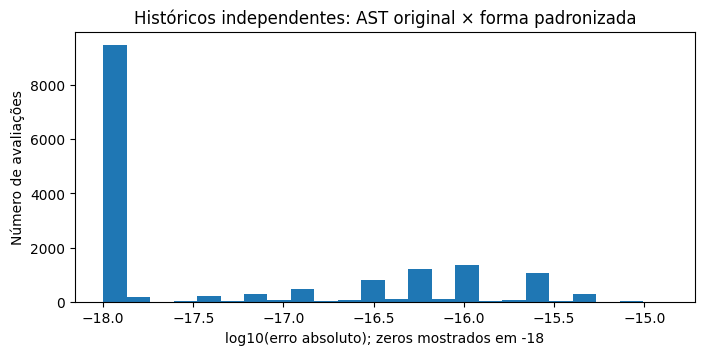

In [13]:
audit_config=RandomTreeConfig(minimum_operators=1,maximum_operators=10,num_series=3,
    minimum_lag=1, maximum_lag=6, parameter_probability=.4, lag_probability=.6)
history_rng=np.random.default_rng(6027)
audit_accepted=0
audit_rejected=0
audit_errors=[]
for seed in range(1000,1250):
    sampled=sample_random_mechanism(audit_config,seed=seed)
    try:
        normal=canonicalize_polynomial(sampled.expression,sampled.binding)
    except ValueError as exc:
        assert 'degree' in str(exc)
        audit_rejected+=1
        continue
    assert normal.canonical_key==oracle_key(sampled.expression,sampled.binding),seed
    for _ in range(64):
        histories={series:history_rng.uniform(-1.,1.,6).tolist() for series in range(3)}
        expected=evaluate_bound_expression(sampled.expression,sampled.binding,time=6,histories=histories)
        actual=normal.evaluate(histories,time=6)
        assert np.isclose(expected,actual,atol=1e-12,rtol=1e-12),(seed,expected,actual)
        audit_errors.append(abs(expected-actual))
    audit_accepted+=1
assert audit_accepted+audit_rejected==250
display(pd.DataFrame([{'Árvores sorteadas':250,'Aceitas':audit_accepted,'Rejeitadas por grau':audit_rejected,
    'Históricos independentes por árvore':64,'Avaliações numéricas':len(audit_errors),
    'Maior erro absoluto':max(audit_errors),'Discordâncias exatas com SymPy':0}]))
fig,ax=plt.subplots(figsize=(8,3.5))
ax.hist(np.log10(np.maximum(audit_errors,1e-18)),bins=24)
ax.set_xlabel('log10(erro absoluto); zeros mostrados em -18')
ax.set_ylabel('Número de avaliações')
ax.set_title('Históricos independentes: AST original × forma padronizada')
plt.show()

Cada valor de cada série e lag é sorteado independentemente, aumentando a cobertura além da linha usada para as figuras iniciais. A comparação com SymPy valida a forma algébrica; os testes numéricos verificam a integração com a avaliação das séries. Estas verificações cobrem os contratos e casos apresentados, sem estender a garantia para `tanh` ou entradas rejeitadas pelo limite de expansão.

### Históricos e instante de avaliação

O instante `t` deve ser compartilhado por todas as séries. A avaliação agora aceita `time=t`, alinhado ao avaliador original da AST; quando `time` é omitido, os históricos das séries utilizadas devem ter o mesmo comprimento.

In [14]:
normal=canonicalize_polynomial(add(u,v),MechanismBinding({},{'U':1,'V':2}))
history_cases=[
 ('Históricos de tamanhos diferentes',{0:[1.,2.,99.],1:[3.,4.]},{},'share a length'),
 ('Histórico curto',{0:[1.],1:[2.]},{'time':1},'unavailable'),
 ('Série ausente',{0:[1.,2.]},{},'Missing history'),
]
history_rows=[]
for name,histories,options,expected in history_cases:
    try: normal.evaluate(histories,**options)
    except ValueError as exc:
        assert expected in str(exc)
        history_rows.append({'Caso':name,'Resultado':str(exc),'Status':'PASS'})
    else: raise AssertionError(name)
assert normal.evaluate({0:[1.,2.,99.],1:[3.,4.]},time=2)==5.
history_rows.append({'Caso':'Tempo explícito t=2 com históricos de tamanhos diferentes','Resultado':'s_0[1]+s_1[0] = 2+3 = 5','Status':'PASS'})
display(pd.DataFrame(history_rows))

,Caso,Resultado,Status
0,Históricos de tamanhos diferentes,"Histories must share a length, or supply an explicit time.",PASS
1,Histórico curto,History for s_1[t-2] is unavailable at t=1.,PASS
2,Série ausente,Missing history for series 1.,PASS
3,Tempo explícito t=2 com históricos de tamanhos diferentes,s_0[1]+s_1[0] = 2+3 = 5,PASS


Os testes acima verificam que cada lag consulta a posição temporal correta e que históricos insuficientes geram uma mensagem explícita.

### Por que a padronização funciona no escopo definido

Cada lag resolvido é uma variável formal distinta e cada parâmetro vinculado é um racional exato correspondente ao float recebido. Uma folha representa um polinômio constante ou de grau um. Se os mapas dos filhos representam suas funções corretamente, unir coeficientes calcula sua soma, e convoluir monômios calcula seu produto pela distributividade. Por indução sobre os nós da árvore, o mapa final representa o mesmo polinômio. Ordenar as chaves e remover somente coeficientes exatamente zero dá uma representação única em termos desses monômios, dentro desse domínio de coeficientes e IDs fixos.

A enumeração e o oráculo independente verificam a implementação dessa regra. Relações particulares entre séries observadas, mudanças de nomes de séries ou arredondamentos ao executar a expressão não são identidades desse anel polinomial. Por exemplo, duas séries que coincidiram numa trajetória continuam sendo variáveis distintas. A comparação canônica preserva essa distinção.

## Dez polinômios intermediários entre os exemplos e o caso extremo

Para medir como a expansão cresce, usamos $A_m^4$, com $A_m = 1 + \sum_{i=1}^{m} z_i$. Os $z_i$ são lags distintos, em ordem de série e atraso, escolhidos entre os 18 disponíveis (3 séries × 6 lags). Fazemos $m=2,3,4,5,6,8,9,10,12,15$. Isso produz, respectivamente, 15, 35, 70, 126, 210, 495, 715, 1.001, 1.820 e 3.876 monômios; o caso extremo tem 7.315. Cada árvore é o produto binário de quatro somas. O notebook confere cada chave e coeficiente pela fórmula multinomial antes de cronometrar as mesmas 5.000 transformações por linha.

In [15]:
from itertools import combinations_with_replacement
from collections import Counter
from math import comb, factorial, prod
from tsfmxai.representations import node_count

intermediate_sizes = (2, 3, 4, 5, 6, 8, 9, 10, 12, 15)
all_lag_atoms = tuple((series, lag) for series in range(3) for lag in range(1, 7))
intermediate_rows = []
for number_of_lags in intermediate_sizes:
    atoms = all_lag_atoms[:number_of_lags]
    base = add(Parameter('offset'), *[Lag(series, f'S{series}_L{lag}') for series, lag in atoms])
    expression = mul(mul(base, base), mul(base, base))
    binding = MechanismBinding({'offset': 1.0},
        {f'S{series}_L{lag}': lag for series, lag in atoms})
    normal = canonicalize_polynomial(expression, binding)

    # Verificação independente da própria expansão: suporte e coeficientes multinomiais.
    expected_keys = tuple(key for degree in range(5)
                          for key in combinations_with_replacement(atoms, degree))
    assert normal.skeleton == expected_keys
    assert len(normal.terms) == comb(number_of_lags+4, 4)
    assert operator_count(expression) == 4*number_of_lags+3
    assert node_count(expression) == 8*number_of_lags+7
    for term in normal.terms:
        degree = len(term.monomial)
        denominator = factorial(4-degree) * prod(
            factorial(count) for count in Counter(term.monomial).values())
        assert term.coefficient_exact == factorial(4) // denominator

    label = f'Intermediário m={number_of_lags}: {len(normal.terms)} termos'
    print('Validado:', label, '| iniciando 5.000 transformações', flush=True)
    measured = benchmark_transform(expression, binding, label,
                                   progress=number_of_lags >= 12)
    intermediate_rows.append({
        'Caso': label,
        'Motivação': f'Crescimento da expansão para {number_of_lags} lags distintos.',
        'Entrada compacta': f'(1 + soma dos primeiros {number_of_lags} lags)^4',
        'Número de lags': number_of_lags,
        'Nós AST': node_count(expression),
        'Coeficientes verificados': len(normal.terms),
        **measured,
    })
    print('Concluído:', label, '| média',
          f"{measured['Tempo médio em 5.000 (µs/transformação)']/1000:.3f} ms",
          flush=True)
assert len(intermediate_rows) == 10
display(pd.DataFrame(intermediate_rows))

Validado: Intermediário m=2: 15 termos | iniciando 5.000 transformações


Concluído: Intermediário m=2: 15 termos | média 0.373 ms


Validado: Intermediário m=3: 35 termos | iniciando 5.000 transformações


Concluído: Intermediário m=3: 35 termos | média 0.773 ms


Validado: Intermediário m=4: 70 termos | iniciando 5.000 transformações


Concluído: Intermediário m=4: 70 termos | média 1.547 ms


... (31 outputs left out)

Intermediário m=15: 3876 termos: 4500/5000 transformações; média do bloco 83.263 ms


Intermediário m=15: 3876 termos: 5000/5000 transformações; média do bloco 83.366 ms


Concluído: Intermediário m=15: 3876 termos | média 77.621 ms


,Caso,Motivação,Entrada compacta,Número de lags,Nós AST,Coeficientes verificados,Operadores AST,Termos de saída,Tempo médio em 5.000 (µs/transformação)
0,Intermediário m=2: 15 termos,Crescimento da expansão para 2 lags distintos.,(1 + soma dos primeiros 2 lags)^4,2,23,15,11,15,373.23894
1,Intermediário m=3: 35 termos,Crescimento da expansão para 3 lags distintos.,(1 + soma dos primeiros 3 lags)^4,3,31,35,15,35,772.87942
2,Intermediário m=4: 70 termos,Crescimento da expansão para 4 lags distintos.,(1 + soma dos primeiros 4 lags)^4,4,39,70,19,70,1546.99310
3,Intermediário m=5: 126 termos,Crescimento da expansão para 5 lags distintos.,(1 + soma dos primeiros 5 lags)^4,5,47,126,23,126,2437.14424
4,Intermediário m=6: 210 termos,Crescimento da expansão para 6 lags distintos.,(1 + soma dos primeiros 6 lags)^4,6,55,210,27,210,3966.45124
5,Intermediário m=8: 495 termos,Crescimento da expansão para 8 lags distintos.,(1 + soma dos primeiros 8 lags)^4,8,71,495,35,495,9443.76210
6,Intermediário m=9: 715 termos,Crescimento da expansão para 9 lags distintos.,(1 + soma dos primeiros 9 lags)^4,9,79,715,39,715,13828.13484
7,Intermediário m=10: 1001 termos,Crescimento da expansão para 10 lags distintos.,(1 + soma dos primeiros 10 lags)^4,10,87,1001,43,1001,19250.61434
8,Intermediário m=12: 1820 termos,Crescimento da expansão para 12 lags distintos.,(1 + soma dos primeiros 12 lags)^4,12,103,1820,51,1820,35416.46768
9,Intermediário m=15: 3876 termos,Crescimento da expansão para 15 lags distintos.,(1 + soma dos primeiros 15 lags)^4,15,127,3876,63,3876,77620.72520


A tabela acima reúne, por linha, a motivação, a entrada compacta, o tamanho da AST, o número de monômios e o tempo médio. Os coeficientes multinomiais validam a forma canônica; o cronômetro mede apenas a transformação. As dez linhas também entram na tabela consolidada ao final, antes do caso extremo.

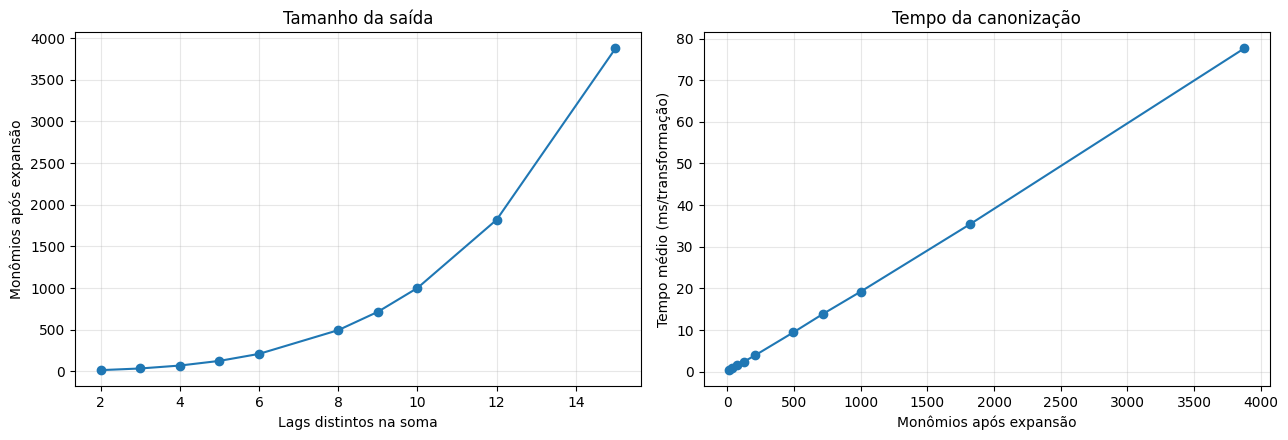

In [16]:
intermediate_df = pd.DataFrame(intermediate_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(intermediate_df['Número de lags'],
             intermediate_df['Termos de saída'], marker='o')
axes[0].set_xlabel('Lags distintos na soma')
axes[0].set_ylabel('Monômios após expansão')
axes[0].set_title('Tamanho da saída')
axes[1].plot(intermediate_df['Termos de saída'],
             intermediate_df['Tempo médio em 5.000 (µs/transformação)']/1000,
             marker='o')
axes[1].set_xlabel('Monômios após expansão')
axes[1].set_ylabel('Tempo médio (ms/transformação)')
axes[1].set_title('Tempo da canonização')
for ax in axes: ax.grid(alpha=.3)
fig.tight_layout()
plt.show()

Os gráficos relacionam tamanho da entrada, tamanho expandido e tempo medido. A curva é empírica para essa família de fórmulas e esse hardware; a quantidade de termos finais não determina sozinha o custo de outras árvores.

## Última linha: suporte máximo para 3 séries, 6 lags e grau quatro

Definimos A = 1 + soma de todos os 18 lags s_j[t-l], para j=0,1,2 e l=1,...,6, e construímos A × A × A × A. A árvore tem 75 operadores. Sua expansão contém todos os monômios possíveis de grau 0 a 4: C(22,4)=7.315 termos. O suporte é máximo nesse conjunto de variáveis e grau; o comprimento da árvore de entrada pode crescer ainda mais mediante repetições. A verificação usa a identidade multinomial, incluindo todos os coeficientes. A última linha da tabela consolidada recebe o tempo médio das mesmas 5.000 transformações.

In [17]:
from itertools import combinations_with_replacement
from collections import Counter
from math import comb, factorial, prod
from tsfmxai.representations import node_count
stress_label = 'Extremo: 18 lags, grau 4, 7.315 termos'
stress_atoms = tuple((series, lag) for series in range(3) for lag in range(1, 7))
stress_sum = add(Parameter('offset'), *[Lag(series, f'S{series}_L{lag}') for series, lag in stress_atoms])
stress_expression = mul(mul(stress_sum, stress_sum), mul(stress_sum, stress_sum))
stress_binding = MechanismBinding({'offset':1.0}, {f'S{series}_L{lag}':lag for series,lag in stress_atoms})
stress_normal = canonicalize_polynomial(stress_expression, stress_binding)
expected_keys = tuple(key for degree in range(5) for key in combinations_with_replacement(stress_atoms,degree))
assert stress_normal.skeleton == expected_keys
assert len(stress_normal.terms) == comb(22,4) == 7315
assert operator_count(stress_expression) == 75
assert node_count(stress_expression) == 151
for term in stress_normal.terms:
    degree = len(term.monomial)
    denominator = factorial(4-degree) * prod(factorial(count) for count in Counter(term.monomial).values())
    assert term.coefficient_exact == factorial(4) // denominator
degree_counts = Counter(len(term.monomial) for term in stress_normal.terms)
display(pd.DataFrame([{'Grau':degree,'Monômios calculados':degree_counts[degree],
                      'Monômios esperados':comb(18+degree-1,degree)}
                     for degree in range(5)]))
print('Suporte e 7.315 coeficientes conferidos exatamente. Iniciando 5.000 transformações...',flush=True)
stress_timing = benchmark_transform(stress_expression, stress_binding, stress_label, progress=True)
display(pd.DataFrame([{
    'Caso':stress_label,
    'Motivação':'Cobrir todos os monômios de grau até 4 em 18 lags.',
    'Entrada compacta':'(1 + sum_{j=0..2, lag=1..6} s_j[t-lag])^4',
    'Saída compacta':'Soma de 7.315 monômios com coeficientes multinomiais',
    'Nós AST':node_count(stress_expression),
    'Validação exata':'7.315/7.315 coeficientes e suporte corretos',
    **stress_timing,
}]))
assert timing_records[-1]['Transformações'] == 5000
print('Tempo médio do caso extremo (ms):',timing_records[-1]['Média (µs/transformação)']/1000,flush=True)

,Grau,Monômios calculados,Monômios esperados
0,0,1,1
1,1,18,18
2,2,171,171
3,3,1140,1140
4,4,5985,5985


Suporte e 7.315 coeficientes conferidos exatamente. Iniciando 5.000 transformações...


Extremo: 18 lags, grau 4, 7.315 termos: 500/5000 transformações; média do bloco 164.064 ms


Extremo: 18 lags, grau 4, 7.315 termos: 1000/5000 transformações; média do bloco 160.059 ms


Extremo: 18 lags, grau 4, 7.315 termos: 1500/5000 transformações; média do bloco 161.661 ms


Extremo: 18 lags, grau 4, 7.315 termos: 2000/5000 transformações; média do bloco 164.652 ms


... (4 outputs left out)

Extremo: 18 lags, grau 4, 7.315 termos: 4500/5000 transformações; média do bloco 160.040 ms


Extremo: 18 lags, grau 4, 7.315 termos: 5000/5000 transformações; média do bloco 163.415 ms


,Caso,Motivação,Entrada compacta,Saída compacta,Nós AST,Validação exata,Operadores AST,Termos de saída,Tempo médio em 5.000 (µs/transformação)
0,"Extremo: 18 lags, grau 4, 7.315 termos",Cobrir todos os monômios de grau até 4 em 18 lags.,"(1 + sum_{j=0..2, lag=1..6} s_j[t-lag])^4",Soma de 7.315 monômios com coeficientes multinomiais,151,7.315/7.315 coeficientes e suporte corretos,75,7315,161711.334


Tempo médio do caso extremo (ms): 161.711334


O cronômetro inclui toda a canonização: validação, distribuição das somas e produtos, agrupamento, cálculo racional e ordenação dos termos. A fórmula de entrada compacta representa a AST de 151 nós; a forma expandida completa está disponível em `stress_normal`. Os coeficientes e o suporte foram verificados antes de medir o tempo. O caso aparece na última linha da tabela seguinte; o gráfico usa escala logarítmica para manter visíveis os exemplos pequenos.

## Tempo de canonização por fórmula

Cada média vem de 5.000 transformações completas da mesma AST e binding. Os 10 blocos de 500 permitem observar a variação do tempo durante a medição. O tempo inclui o cálculo simbólico e racional dos coeficientes. As linhas com entrada rejeitada não entram nesta comparação de transformações bem-sucedidas.

,Caso,Transformações,Operadores AST,Termos de saída,Média (µs/transformação),DP das médias dos 10 blocos (µs),Tempo total das 5.000 (s)
0,01 Constante,5000,0,1,18.37496,2.003556,0.091875
1,02 Um lag,5000,0,1,12.23560,3.156017,0.061178
2,03 Offset + lag,5000,1,2,29.09664,4.507568,0.145483
3,04 Lags fora de ordem,5000,1,2,28.50562,0.678449,0.142528
4,05 Alias de lag,5000,1,1,18.46626,3.471168,0.092331
5,06 Mesmo lag ao quadrado,5000,1,1,20.57656,3.711960,0.102883
6,07 Interação multivariada,5000,1,1,20.92662,3.920217,0.104633
7,08 Distribuição simples,5000,2,2,41.99138,5.595116,0.209957
8,09 Duas somas,5000,3,4,69.63366,7.783541,0.348168
9,10 Termos iguais após expansão,5000,3,3,53.65718,7.678473,0.268286


Linhas medidas: 72
Total de transformações cronometradas: 360000
Intervalo de médias (µs/transformação): 12.235599999999998 161711.334


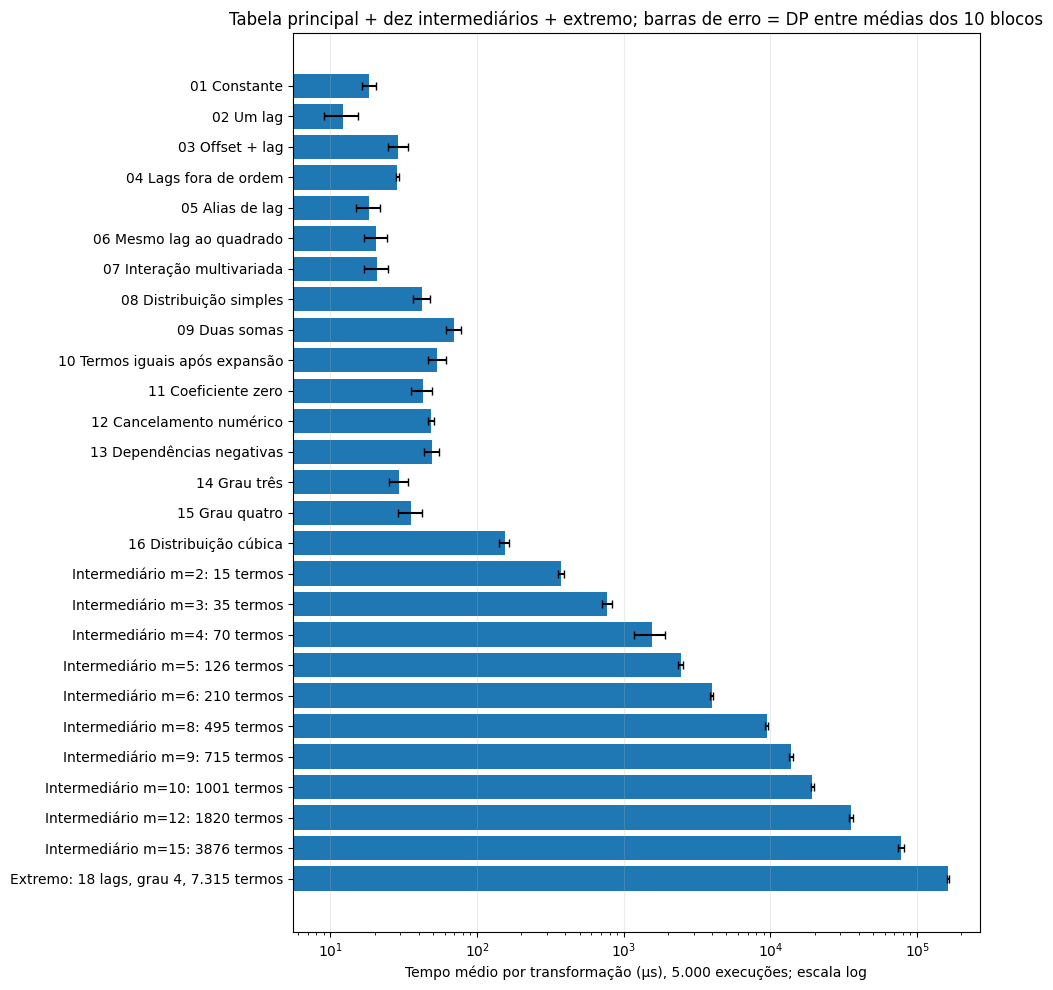

In [18]:
timing_df = pd.DataFrame(timing_records)
assert len(timing_df) == len(cases) + len(random_rows) + len(edge_cases) + len(equivalence_rows) + len(intermediate_sizes) + 1
assert timing_df['Transformações'].eq(5000).all()
display(timing_df)
print('Linhas medidas:', len(timing_df))
print('Total de transformações cronometradas:', int(timing_df['Transformações'].sum()))
print('Intervalo de médias (µs/transformação):',
      float(timing_df['Média (µs/transformação)'].min()),
      float(timing_df['Média (µs/transformação)'].max()))
assert timing_df.iloc[-1]['Caso'] == stress_label
main_times = pd.concat([timing_df.iloc[:len(cases)], timing_df.tail(len(intermediate_sizes)+1)])
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(main_times['Caso'], main_times['Média (µs/transformação)'],
        xerr=main_times['DP das médias dos 10 blocos (µs)'], capsize=3)
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xlabel('Tempo médio por transformação (µs), 5.000 execuções; escala log')
ax.set_title('Tabela principal + dez intermediários + extremo; barras de erro = DP entre médias dos 10 blocos')
ax.grid(axis='x', alpha=.25)
fig.tight_layout()
plt.show()

A tabela registra a média, a variabilidade entre blocos e o tempo total gasto nas 5.000 chamadas de cada linha. A complexidade depende tanto dos nós percorridos quanto dos termos criados durante a expansão e dos cálculos de coeficientes; duas fórmulas com a mesma quantidade de termos finais podem exigir trabalho diferente. Os valores descrevem esta execução local e podem oscilar com a carga da máquina.